# Low-Risk Portfolio Allocation: Quick Start

This executed example inspects the final-report results, verifies key accounting identities, and computes a new allocation from an actual raw-data window. Install the repository with `python -m pip install -r requirements.txt` and retrieve the data with `git lfs pull` first.

The primary experiment uses the supplied 30-stock selections, 36-month estimation windows, and one-way costs of 10 basis points. This notebook does not reconstruct the upstream stock selector.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from lowrisk_portfolio.paths import ROOT
from lowrisk_portfolio.selection import load_selection
from lowrisk_portfolio.models import allocate
from lowrisk_portfolio.data import read_factors

reference = ROOT / "results/reference"
selection = load_selection(ROOT / "data/selections/defensive_selection.csv", expected_n=30)
metrics = pd.read_csv(reference / "model_metrics.csv")
returns = pd.read_csv(reference / "monthly_returns.csv")
holdings = pd.read_csv(reference / "holdings.csv.gz")
primary = returns.query("scenario == 'total_observed_drift10'")
print(f"{selection.holding_month.nunique()} holding months; {len(selection):,} selected stock-months; {primary.model.nunique()} allocation rules")

215 holding months; 6,450 selected stock-months; 19 allocation rules


## Inspect the main results

Returns and weights are stored as decimal fractions. Sharpe uses monthly risk-free-adjusted returns and annualization by the square root of 12.

In [2]:
summary = metrics.query("scenario == 'total_observed_drift10' and period == 'full'").set_index("model")
columns = ["cagr", "annual_volatility", "sharpe", "max_drawdown"]
display(summary[columns].sort_values("sharpe", ascending=False).style.format({"cagr": "{:.2%}", "annual_volatility": "{:.2%}", "sharpe": "{:.3f}", "max_drawdown": "{:.2%}"}))

,cagr,annual_volatility,sharpe,max_drawdown
model,,,,
gmvp_lw_identity,13.48%,10.82%,1.114,-31.16%
source_weight,14.05%,11.39%,1.110,-29.00%
mix_1n,13.46%,10.94%,1.102,-31.55%
gmvp_ridge,13.35%,10.88%,1.098,-31.88%
gmvp_sample,13.36%,10.91%,1.096,-32.58%
norm_gmvp,13.36%,10.91%,1.096,-32.58%
equal_weight,13.52%,11.18%,1.087,-30.77%
inverse_vol,13.44%,11.11%,1.086,-30.80%
gmvp_qis,13.18%,10.87%,1.085,-31.06%


## Verify constraints and trading-cost accounting

In [3]:
groups = holdings.groupby(["holding_month", "model"])
assert groups.size().eq(30).all()
np.testing.assert_allclose(groups.weight.sum(), 1, atol=1e-6)
assert holdings.weight.between(-1e-9, 2/30 + 1e-6).all()
np.testing.assert_allclose(primary.net_return, (1 - 0.001 * primary.traded_notional) * (1 + primary.gross_return) - 1, atol=1e-12)
assert primary.groupby("model").size().eq(215).all()
print("Verified: common stock count, budget, position limits, monthly coverage, and cost identity.")

Verified: common stock count, budget, position limits, monthly coverage, and cost identity.


## Visualize cumulative wealth

The primary benchmark is the CRSP value-weighted total-return market. The S&P 500 price index is included as a secondary comparison; it excludes dividends. The strategy series include dividends and transaction costs.

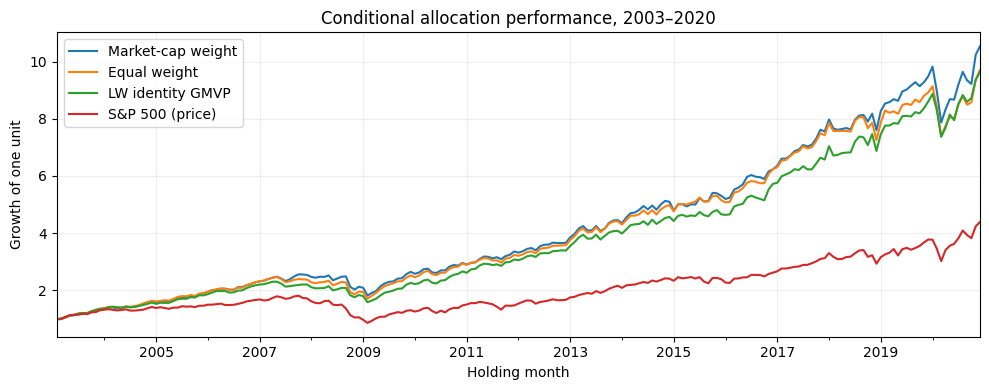

In [4]:
selected_models = {"source_weight": "Market-cap weight", "equal_weight": "Equal weight", "gmvp_lw_identity": "LW identity GMVP"}
wide = primary.pivot(index="month", columns="model", values="net_return")
benchmarks = pd.read_csv(reference / "benchmark_returns.csv", index_col="month")
view = wide[list(selected_models)].rename(columns=selected_models).join(benchmarks[["CRSP_market", "SP500"]].rename(columns={"CRSP_market": "CRSP market (total return)", "SP500": "S&P 500 (price)"}))
view.index = pd.PeriodIndex(view.index, freq="M").to_timestamp("M")
ax = (1 + view).cumprod().plot(figsize=(10, 4), linewidth=1.5)
ax.set(ylabel="Growth of one unit", xlabel="Holding month", title="Conditional allocation performance, 2003–2020")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## Compute allocations from a real estimation window

Read the original monthly input in chunks and retain the first selection’s 30 stocks. No forward filling or return imputation is used. The following weights are an estimation example, not a backtest.

In [5]:
first_month = selection.holding_month.min()
selected = selection.loc[selection.holding_month.eq(first_month), "PERMNO"]
formation = first_month - 1
chunks = []
for chunk in pd.read_csv(ROOT / "data/raw/security_monthly.csv.gz", usecols=["PERMNO", "YYYYMM", "MthRet"], chunksize=250_000):
    keep = chunk.PERMNO.isin(selected) & chunk.YYYYMM.between(int(str(formation - 35).replace("-", "")), int(str(formation).replace("-", "")))
    chunks.append(chunk.loc[keep])
raw = pd.concat(chunks, ignore_index=True).drop_duplicates()
assert not raw.duplicated(["PERMNO", "YYYYMM"]).any(), "Conflicting security-month source records"
raw["month"] = pd.PeriodIndex(raw.YYYYMM.astype(str), freq="M")
history = raw.pivot(index="month", columns="PERMNO", values="MthRet").reindex(columns=selected)
assert history.shape == (36, 30) and np.isfinite(history.to_numpy()).all()
factors = read_factors(ROOT / "data/raw/factor_returns_monthly.csv").loc[history.index]
example = pd.DataFrame({model: allocate(model, history, pd.Series(index=history.columns, dtype=float), factors, pd.Series(dtype=float), cap=2/30, cost=0.002) for model in ["equal_weight", "gmvp_lw_identity", "min_cvar"]})
np.testing.assert_allclose(example.sum(), 1, atol=1e-6)
assert example.ge(-1e-9).all().all() and example.le(2/30 + 1e-6).all().all()
display(example.head(10).style.format("{:.4%}"))
print(f"Computed allocations for holding month {first_month} from {history.index.min()} through {history.index.max()}.")

./src/lowrisk_portfolio/optimizers/cov_lw_identity.py:12: RuntimeWarning: divide by zero encountered in matmul
  S = Y.T @ Y / T
./src/lowrisk_portfolio/optimizers/cov_lw_identity.py:12: RuntimeWarning: overflow encountered in matmul
  S = Y.T @ Y / T
./src/lowrisk_portfolio/optimizers/cov_lw_identity.py:12: RuntimeWarning: invalid value encountered in matmul
  S = Y.T @ Y / T


,equal_weight,gmvp_lw_identity,min_cvar
PERMNO,,,
59184,3.3333%,4.8689%,6.6667%
85925,3.3333%,3.1740%,0.7959%
79072,3.3333%,1.6210%,0.0000%
86106,3.3333%,6.6667%,6.6667%
76932,3.3333%,5.6870%,2.1549%
85763,3.3333%,6.6667%,6.6667%
10777,3.3333%,0.3990%,0.0000%
34367,3.3333%,1.9422%,0.0000%
26825,3.3333%,3.3676%,6.6667%


Computed allocations for holding month 2003-02 from 2000-02 through 2003-01.


## Interpretation

The published comparison is conditional on fixed historical selections. Small differences in sample Sharpe are not, by themselves, evidence of an improvement. Run `02_reproduce_report.ipynb` for the complete pipeline and numerical reference comparison.